In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
import nibabel as nib

import sys
sys.path.append("/home/agustin/phd/synthesis/utils")

import util_freesurfer_segmentation as ufs



from cornucopia import ContrastMixtureTransform


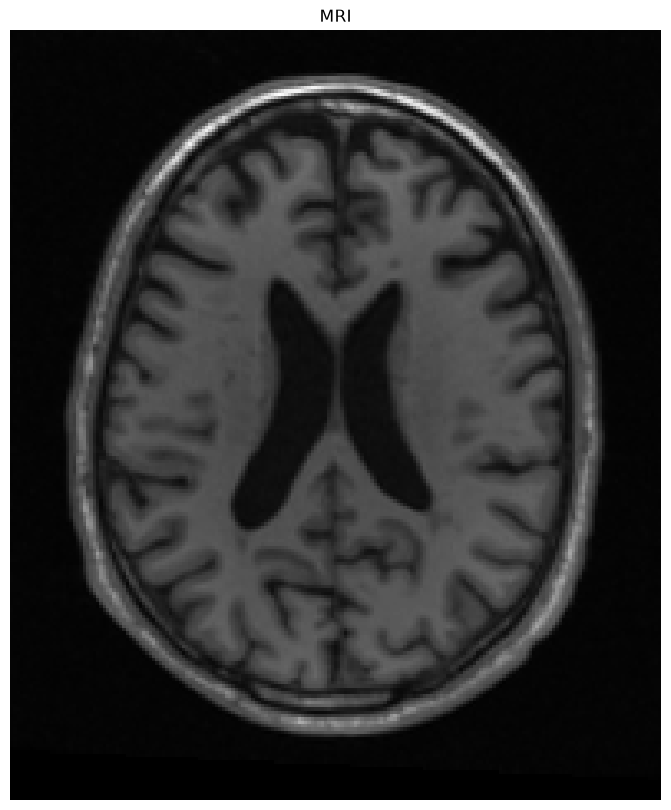

In [10]:
fname_img = "data/inputs/sub-ADNI002S0295_ses-m000_space-MNI_T1w.nii.gz"

img = nib.load(fname_img).get_fdata()
img = np.flipud(img[:, :, img.shape[2] // 2].T).copy()
dat = torch.as_tensor(img)

plt.figure(figsize=(10, 10))
plt.imshow(dat, cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('MRI')
plt.show()

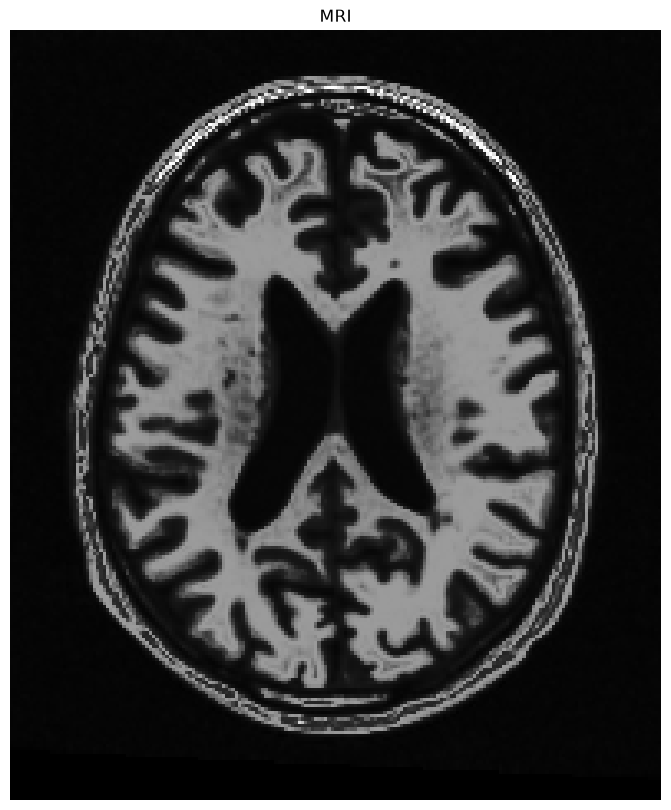

In [20]:
trf = ContrastMixtureTransform(nk=6)
aug = trf(dat[None])[0]

plt.figure(figsize=(10, 10))
plt.imshow(aug, cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('MRI')
plt.show()

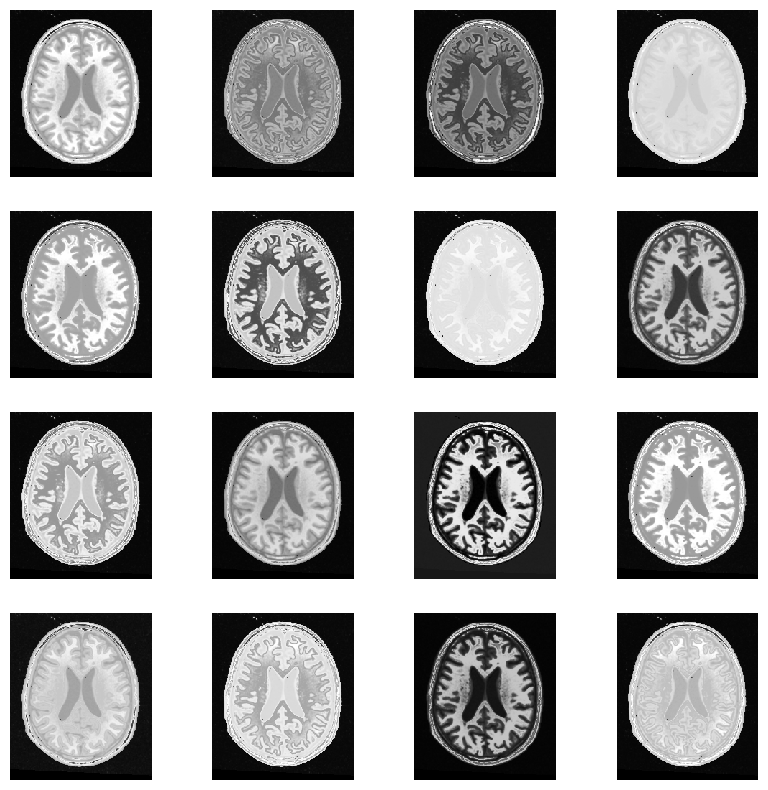

In [21]:
shape = [4, 4]

plt.figure(figsize=(10, 10))
for i in range(shape[0] * shape[1]):
    plt.subplot(*shape, i+1)
    plt.imshow(trf(dat[None])[0], cmap='gray', interpolation='nearest')
    plt.axis('off')
plt.show()